# CH20 – Air Quality Insight

An evidence-based analysis of the supplied air-quality, station, weather, traffic, and calendar CSV files.

## Objective
Analyze how station and time relate to pollution, validate whether weather/traffic joins are defensible, and produce actionable recommendations without fabricating unavailable measurements.

In [1]:
import sys, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
print(sys.executable)
print(sys.version)

C:\Users\HARIPRIYAN\Downloads\Air_Quality_Insight\.venv\Scripts\python.exe
3.11.15 (main, May 10 2026, 19:31:25) [MSC v.1944 64 bit (AMD64)]


In [2]:
DATA_DIR = Path.cwd()
air_quality = pd.read_csv(DATA_DIR / 'air_quality.csv', parse_dates=['timestamp'])
stations = pd.read_csv(DATA_DIR / 'stations.csv')
weather = pd.read_csv(DATA_DIR / 'weather.csv', parse_dates=['timestamp'])
traffic = pd.read_csv(DATA_DIR / 'traffic.csv', parse_dates=['Date'])
calendar = pd.read_csv(DATA_DIR / 'calendar.csv', parse_dates=['timestamp'])
{ name: df.shape for name, df in {'air_quality': air_quality, 'stations': stations, 'weather': weather, 'traffic': traffic, 'calendar': calendar}.items() }

{'air_quality': (108035, 16),
 'stations': (230, 5),
 'weather': (7732, 3),
 'traffic': (8936, 16),
 'calendar': (2961, 6)}

## Audit and compatibility
The following report is generated from the actual files. Weather and traffic are intentionally not merged with air quality because their dates and join keys are incompatible.

In [3]:
print("CH20 – Air Quality Insight: Data Audit\nGenerated with C:\\Users\\HARIPRIYAN\\Downloads\\Air_Quality_Insight\\.venv\\Scripts\\python.exe\n\nDataset source note: CSV files were supplied in the project workspace. No external source metadata was included in the files.\n\n=== air_quality ===\nRows: 108,035\nColumns: 16\nColumn names: station, timestamp, PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene, AQI, AQI_Bucket\nDuplicate rows: 0\nData types: station=str; timestamp=datetime64[us]; PM2.5=float64; PM10=float64; NO=float64; NO2=float64; NOx=float64; NH3=float64; CO=float64; SO2=float64; O3=float64; Benzene=float64; Toluene=float64; Xylene=float64; AQI=float64; AQI_Bucket=str\nMissing values: PM2.5=21,625; PM10=42,706; NO=17,106; NO2=16,547; NOx=15,500; NH3=48,105; CO=12,998; SO2=25,204; O3=25,568; Benzene=31,455; Toluene=38,702; Xylene=85,137; AQI=21,010; AQI_Bucket=21,010\ntimestamp range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00; invalid after parsing: 0\nstation unique values: 110; examples: ['AP001', 'AP005', 'AS001', 'BR005', 'BR006', 'BR007', 'BR008', 'BR009', 'BR010', 'CH001', 'DL001', 'DL002']\nNegative numeric values: none\nIQR outlier flags (investigate, not deleted): {'PM2.5': 6448, 'PM10': 3084, 'NO': 9869, 'NO2': 3786, 'NOx': 7604, 'NH3': 2241, 'CO': 6460, 'SO2': 5067, 'O3': 2985, 'Benzene': 5987, 'Toluene': 6619, 'Xylene': 2913, 'AQI': 1795}\nAQI > 500 review flags: 1883; retained because the source AQI_Bucket labels these records Severe.\n\n=== stations ===\nRows: 230\nColumns: 5\nColumn names: station, station_name, location, state, status\nDuplicate rows: 0\nData types: station=str; station_name=str; location=str; state=str; status=str\nMissing values: status=97\nstation unique values: 230; examples: ['AP001', 'AP002', 'AP003', 'AP004', 'AP005', 'AS001', 'BR001', 'BR002', 'BR003', 'BR004', 'BR005', 'BR006']\nlocation unique values: 127; examples: ['Agra', 'Ahmedabad', 'Aizawl', 'Ajmer', 'Alwar', 'Amaravati', 'Ambala', 'Amritsar', 'Ankleshwar', 'Asansol', 'Aurangabad', 'Bagalkot']\n\n=== weather ===\nRows: 7,732\nColumns: 3\nColumn names: timestamp, location, weather_condition\nDuplicate rows: 0\nData types: timestamp=datetime64[us]; location=str; weather_condition=str\nMissing values: none\ntimestamp range: 2022-01-01 00:00:00 to 2024-08-09 00:00:00; invalid after parsing: 0\nlocation unique values: 8; examples: ['Electronic City', 'Hebbal', 'Indiranagar', 'Jayanagar', 'Koramangala', 'M.G. Road', 'Whitefield', 'Yeshwanthpur']\n\n=== traffic ===\nRows: 8,936\nColumns: 16\nColumn names: Date, Area Name, Road/Intersection Name, Traffic Volume, Average Speed, Travel Time Index, Congestion Level, Road Capacity Utilization, Incident Reports, Environmental Impact, Public Transport Usage, Traffic Signal Compliance, Parking Usage, Pedestrian and Cyclist Count, Weather Conditions, Roadwork and Construction Activity\nDuplicate rows: 0\nData types: Date=datetime64[us]; Area Name=str; Road/Intersection Name=str; Traffic Volume=int64; Average Speed=float64; Travel Time Index=float64; Congestion Level=float64; Road Capacity Utilization=float64; Incident Reports=int64; Environmental Impact=float64; Public Transport Usage=float64; Traffic Signal Compliance=float64; Parking Usage=float64; Pedestrian and Cyclist Count=int64; Weather Conditions=str; Roadwork and Construction Activity=str\nMissing values: none\nDate range: 2022-01-01 00:00:00 to 2024-08-09 00:00:00; invalid after parsing: 0\nArea Name unique values: 8; examples: ['Electronic City', 'Hebbal', 'Indiranagar', 'Jayanagar', 'Koramangala', 'M.G. Road', 'Whitefield', 'Yeshwanthpur']\nNegative numeric values: none\nIQR outlier flags (investigate, not deleted): {'Traffic Volume': 24, 'Average Speed': 33, 'Congestion Level': 3, 'Road Capacity Utilization': 2078, 'Incident Reports': 100, 'Environmental Impact': 24, 'Pedestrian and Cyclist Count': 1316}\n\n=== calendar ===\nRows: 2,961\nColumns: 6\nColumn names: timestamp, weekday, month, year, season, holiday\nDuplicate rows: 0\nData types: timestamp=datetime64[us]; weekday=str; month=int64; year=int64; season=str; holiday=str\nMissing values: none\ntimestamp range: 2015-01-01 00:00:00 to 2024-08-09 00:00:00; invalid after parsing: 0\nseason unique values: 4; examples: ['Monsoon', 'Post-Monsoon', 'Summer', 'Winter']\nNegative numeric values: none\nIQR outlier flags (investigate, not deleted): none\n\n=== Compatibility checks ===\nAir-quality dates: 2015-01-01 to 2020-07-01\nWeather dates: 2022-01-01 to 2024-08-09\nTraffic dates: 2022-01-01 to 2024-08-09\nAir-quality/weather date overlap: 0 dates\nAir-quality/traffic date overlap: 0 dates\nWeather and traffic use 2022–2024 location/date records; air quality uses 2015–2020 station/timestamp records. No cross-dataset pollution join was made.\nWeather has only categorical weather_condition; wind, rainfall, temperature, and humidity measurements are unavailable.\nTraffic has no AQI or station identifier; traffic volume versus AQI was not calculated.\n\n=== Compatibility matrix ===\nair_quality + stations: JOINABLE by normalized station ID; 110 of 110 air-quality IDs are present in stations (0 unmatched air-quality IDs). This is metadata enrichment only.\nair_quality + calendar: JOINABLE by calendar date; calendar supplies date labels. 2009 of 2009 air-quality dates are present in calendar; timestamp granularity differs, so the join key is date, not timestamp.\nair_quality + weather: NOT ASSESSABLE; 0 overlapping calendar dates and no station/location mapping.\nair_quality + traffic: NOT ASSESSABLE; 0 overlapping calendar dates, no station key, and no AQI field.\nweather + traffic: JOINABLE by date and shared area names for their own 2022–2024 descriptive comparison; this does not create an AQI relationship.\n")

CH20 – Air Quality Insight: Data Audit
Generated with C:\Users\HARIPRIYAN\Downloads\Air_Quality_Insight\.venv\Scripts\python.exe

Dataset source note: CSV files were supplied in the project workspace. No external source metadata was included in the files.

=== air_quality ===
Rows: 108,035
Columns: 16
Column names: station, timestamp, PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene, AQI, AQI_Bucket
Duplicate rows: 0
Data types: station=str; timestamp=datetime64[us]; PM2.5=float64; PM10=float64; NO=float64; NO2=float64; NOx=float64; NH3=float64; CO=float64; SO2=float64; O3=float64; Benzene=float64; Toluene=float64; Xylene=float64; AQI=float64; AQI_Bucket=str
Missing values: PM2.5=21,625; PM10=42,706; NO=17,106; NO2=16,547; NOx=15,500; NH3=48,105; CO=12,998; SO2=25,204; O3=25,568; Benzene=31,455; Toluene=38,702; Xylene=85,137; AQI=21,010; AQI_Bucket=21,010
timestamp range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00; invalid after parsing: 0
station unique values: 11

## Cleaning and feature engineering

In [4]:
aq = air_quality.copy()
aq['station'] = aq['station'].astype('string').str.strip().str.upper()
aq['timestamp'] = pd.to_datetime(aq['timestamp'], errors='coerce')
aq['hour'] = aq['timestamp'].dt.hour
aq['weekday'] = aq['timestamp'].dt.day_name()
aq['month'] = aq['timestamp'].dt.month
aq['year'] = aq['timestamp'].dt.year
aq['season'] = aq['month'].map(lambda m: 'Winter' if m in (12,1,2) else 'Spring' if m in (3,4,5) else 'Summer' if m in (6,7,8) else 'Autumn')
aq.head()

,station,timestamp,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,...,Benzene,Toluene,Xylene,AQI,AQI_Bucket,hour,weekday,month,year,season
0,AP001,2017-11-24,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,...,0.17,5.92,0.10,NaN,NaN,0,Friday,11,2017,Autumn
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,...,0.20,6.50,0.06,184.0,Moderate,0,Saturday,11,2017,Autumn
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,...,0.22,7.95,0.08,197.0,Moderate,0,Sunday,11,2017,Autumn
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,...,0.29,7.63,0.12,198.0,Moderate,0,Monday,11,2017,Autumn
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,...,0.17,5.02,0.07,188.0,Moderate,0,Tuesday,11,2017,Autumn


## Exploratory findings

In [5]:
from IPython.display import display, Image

station_summary = (aq.dropna(subset=['AQI']).groupby('station')['AQI'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False))
display(aq[['AQI'] + [c for c in ['PM2.5', 'PM10', 'NO2', 'NOx'] if c in aq]].describe().T)
display(station_summary.head(10))

,count,mean,std,min,25%,50%,75%,max
AQI,87025.0,179.749290,131.324339,8.00,86.00,132.00,254.00,2049.00
PM2.5,86410.0,80.272571,76.526403,0.02,31.88,55.95,99.92,1000.00
PM10,65329.0,157.968427,123.418672,0.01,70.15,122.09,208.67,1000.00
NO2,91488.0,35.240760,29.510827,0.01,15.09,27.21,46.93,448.05
NOx,92535.0,41.195055,45.145976,0.00,13.97,26.66,50.50,467.63


,mean,median,count
station,,,
GJ001,452.122939,384.5,1334
DL002,355.790272,329.0,1583
DL028,294.303668,312.0,1472
DL038,271.785304,248.0,871
DL020,269.097765,248.5,716
DL015,260.863844,252.0,874
DL010,260.640091,239.0,878
DL008,258.017621,246.5,908
DL034,257.912088,239.0,1183


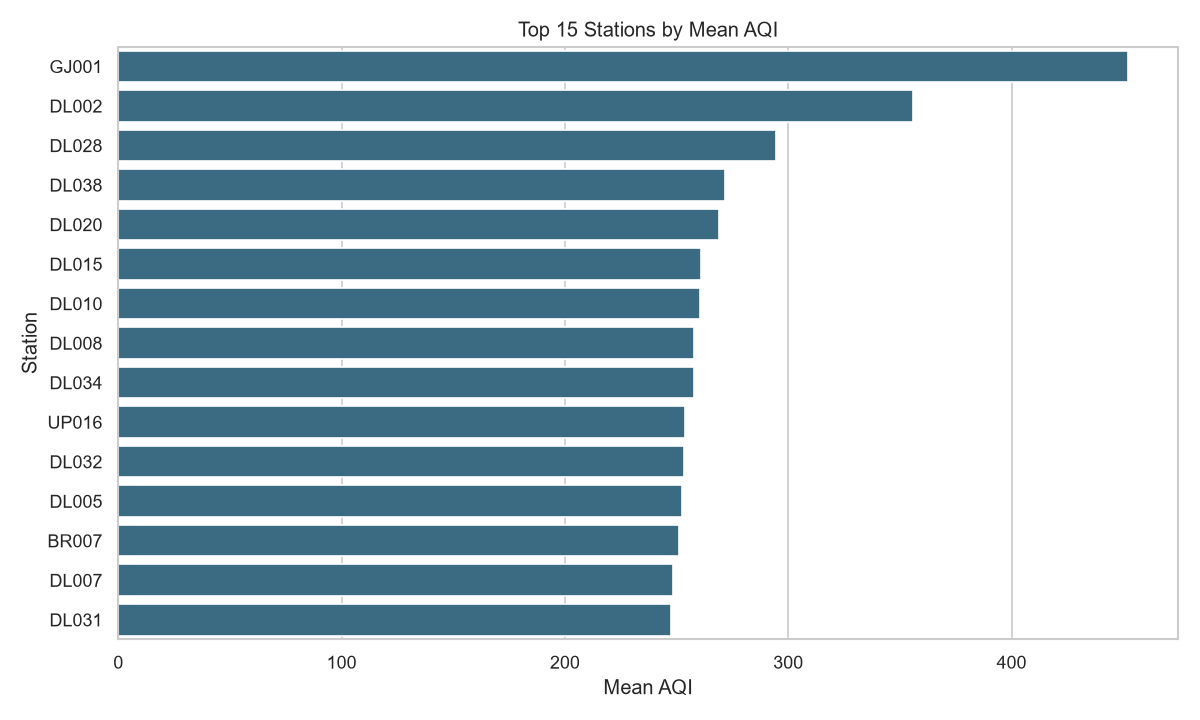

In [6]:
Image(filename=str(DATA_DIR / 'outputs' / 'figures' / 'station_comparison.png'))

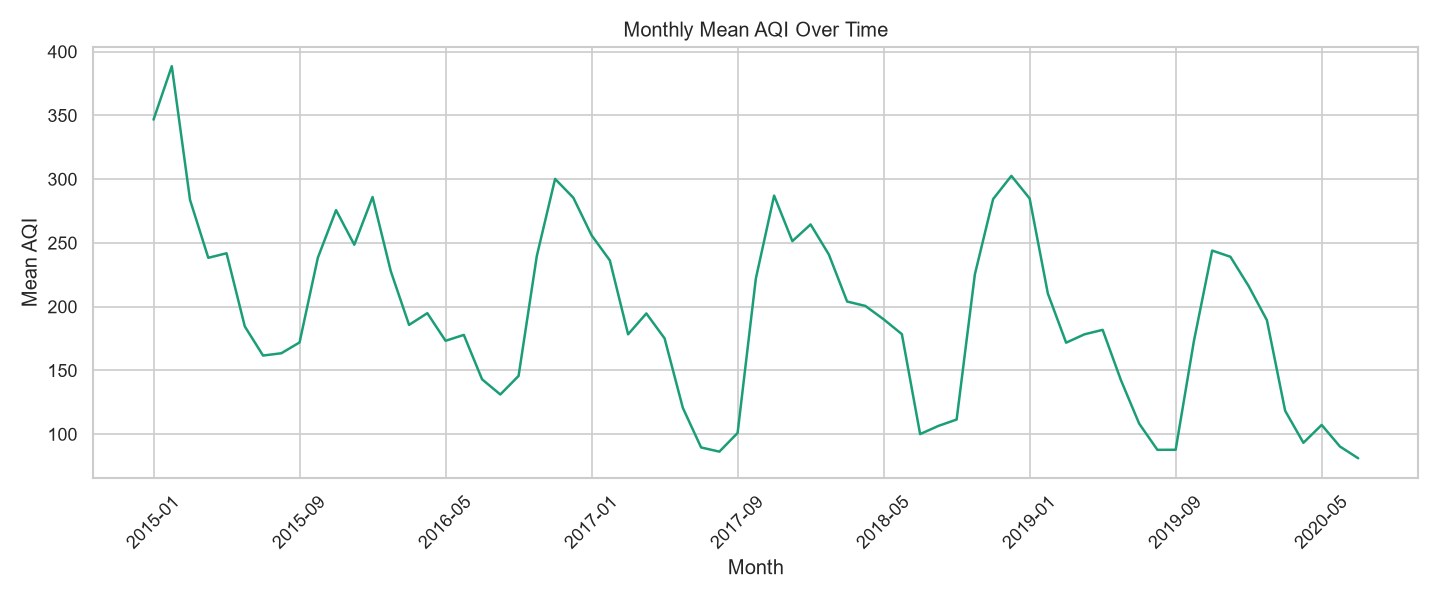

In [7]:
Image(filename=str(DATA_DIR / 'outputs' / 'figures' / 'monthly_trend.png'))

In [8]:
print('CH20 – Evidence-based EDA findings\n\n1. [Supported by data] AQI coverage: 87,025 of 108,035 air-quality records have AQI (80.6%). Mean AQI is 179.75; median is 132.00.\n2. [Supported by data] Station variation: among stations with at least 20 AQI records, GJ001 has the highest mean AQI (452.12) and MZ001 the lowest (34.77); high station n=1334, low station n=111.\n3. [Supported by data] Derived seasonal pattern: Winter has the highest mean AQI (243.48) and Summer the lowest (117.39); seasons are derived from timestamp month, not weather observations.\n4. [Suggestive, not causal] Strongest absolute pollutant correlation with AQI in these records is PM10 (Pearson r=0.885). Correlation is not causation.\n5. [Not assessable with supplied data] Wind, rainfall, temperature and humidity analyses were not performed because the weather file contains only categorical weather_condition and does not overlap the air-quality date range.\n6. [Not assessable with supplied data] Traffic volume versus AQI was not performed because traffic has no AQI/station key and its dates (2022–2024) do not overlap air quality (2015–2020).\n7. [Suggestive, not causal] Chronological same-record AQI estimation: Random Forest MAE=17.46, RMSE=26.97, R²=0.902; training-mean baseline MAE=93.95, RMSE=105.32, R²=-0.492.\n\nThe model estimates same-record AQI from pollutant measurements; it is not a future forecast. AQI is derived from pollutants, so this result should not be interpreted as an independent causal prediction.\n')

CH20 – Evidence-based EDA findings

1. [Supported by data] AQI coverage: 87,025 of 108,035 air-quality records have AQI (80.6%). Mean AQI is 179.75; median is 132.00.
2. [Supported by data] Station variation: among stations with at least 20 AQI records, GJ001 has the highest mean AQI (452.12) and MZ001 the lowest (34.77); high station n=1334, low station n=111.
3. [Supported by data] Derived seasonal pattern: Winter has the highest mean AQI (243.48) and Summer the lowest (117.39); seasons are derived from timestamp month, not weather observations.
4. [Suggestive, not causal] Strongest absolute pollutant correlation with AQI in these records is PM10 (Pearson r=0.885). Correlation is not causation.
5. [Not assessable with supplied data] Wind, rainfall, temperature and humidity analyses were not performed because the weather file contains only categorical weather_condition and does not overlap the air-quality date range.
6. [Not assessable with supplied data] Traffic volume versus AQI was

In [9]:
from IPython.display import display
display(pd.DataFrame([{'model': 'Random Forest regression', 'split': 'chronological final 20%', 'rows_train': 69620, 'rows_test': 17405, 'MAE': 17.464794119516846, 'RMSE': 26.971912138228358, 'R2': 0.9021376181215627}, {'model': 'Training-mean baseline', 'split': 'chronological final 20%', 'rows_train': 69620, 'rows_test': 17405, 'MAE': 93.94881875269706, 'RMSE': 105.32050563784372, 'R2': -0.4921695738286096}]))

,model,split,rows_train,rows_test,MAE,RMSE,R2
0,Random Forest regression,chronological final 20%,69620,17405,17.464794,26.971912,0.902138
1,Training-mean baseline,chronological final 20%,69620,17405,93.948819,105.320506,-0.492170


## Limitations and conclusion
The air-quality dataset supports station/time EDA and same-record AQI estimation. It does not support causal weather or traffic analysis with the supplied files because measurements and compatible keys are unavailable.